In [1]:
from pathlib import Path
import json
import os
import random

import numpy as np
import pandas as pd
import torch

RANDOM_SEED = int(os.environ.get('SKIN_RANDOM_SEED', '42'))
CLASS_NAMES = ('AK', 'BCC', 'MEL', 'NV', 'SCC')
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def findProjectRoot(startPath: Path) -> Path:
    for candidateRoot in (startPath, *startPath.parents):
        if (candidateRoot / 'data' / 'processed').exists() and (candidateRoot / 'notebooks').exists():
            return candidateRoot
    raise RuntimeError('Run from the skin-domain-shift project or one of its subdirectories.')

projectRoot = findProjectRoot(Path.cwd().resolve())
processedRoot = projectRoot / 'data' / 'processed'
artifactRoot = projectRoot / 'artifacts' / 'ds'
figureRoot = projectRoot / 'reports' / 'figures' / 'ds'
reportRoot = projectRoot / 'reports'
artifactRoot.mkdir(parents=True, exist_ok=True)
figureRoot.mkdir(parents=True, exist_ok=True)

def fromProjectPath(pathValue: str) -> Path:
    return (projectRoot / Path(pathValue)).resolve()

runMode = os.environ.get('SKIN_RUN_MODE', 'full').strip().lower()
if runMode not in {'smoke', 'full'}:
    raise ValueError('SKIN_RUN_MODE must be smoke or full.')
runModeRoot = artifactRoot / runMode
runFigureModeRoot = figureRoot / runMode
runArtifactRoot = runModeRoot / f'seed{RANDOM_SEED}'
runFigureRoot = runFigureModeRoot / f'seed{RANDOM_SEED}'
runArtifactRoot.mkdir(parents=True, exist_ok=True)
runFigureRoot.mkdir(parents=True, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Project root: {projectRoot}')
print(f'Run mode: {runMode}; seed: {RANDOM_SEED}')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU Avail')

Project root: D:\sunib\Research\Skin\skin-domain-shift
Run mode: full; seed: 42
Device: cuda
GPU Avail


In [2]:
clinicalMetricsPath = runArtifactRoot / 'clinicalTestMetrics.json'
isicMetricsPath = runArtifactRoot / 'isicDomainShiftMetrics.json'
for metricsPath in (clinicalMetricsPath, isicMetricsPath):
    if not metricsPath.exists():
        raise FileNotFoundError(f'Missing {metricsPath}. Run notebooks 02 and 03 first.')
clinicalMetrics = json.loads(clinicalMetricsPath.read_text(encoding='utf-8'))
isicMetrics = json.loads(isicMetricsPath.read_text(encoding='utf-8'))
assert clinicalMetrics['runMode'] == isicMetrics['runMode'] == runMode
assert clinicalMetrics['randomSeed'] == isicMetrics['randomSeed'] == RANDOM_SEED
assert not isicMetrics['isicUsedForSelection']

,dataset,metric,value,lower95,upper95
0,Clinical test,macroF1,0.555038,0.480441,0.625004
1,Clinical test,balancedAccuracy,0.607180,0.519529,0.685885
2,ISIC external test,macroF1,0.379529,0.362034,0.395845
3,ISIC external test,balancedAccuracy,0.381758,0.362999,0.398570


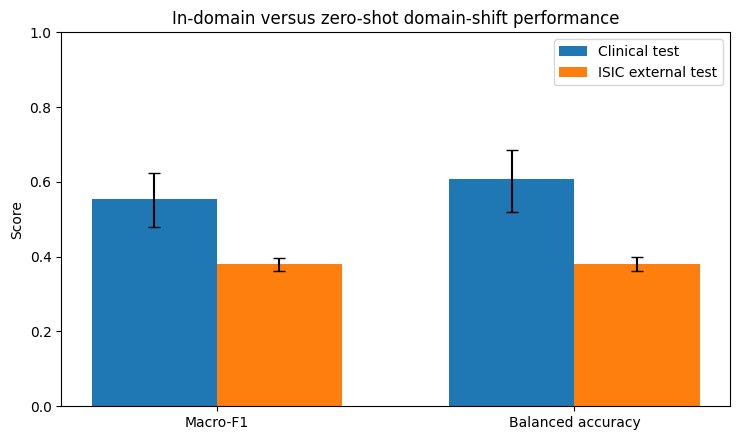

In [3]:
import matplotlib.pyplot as plt

comparisonRows = []
for displayName, metrics in [('Clinical test', clinicalMetrics), ('ISIC external test', isicMetrics)]:
    for metricName in ['macroF1', 'balancedAccuracy']:
        comparisonRows.append({
            'dataset': displayName,
            'metric': metricName,
            'value': metrics[metricName],
            'lower95': metrics['confidenceIntervals'][metricName]['lower95'],
            'upper95': metrics['confidenceIntervals'][metricName]['upper95'],
        })
comparisonFrame = pd.DataFrame(comparisonRows)
display(comparisonFrame)

summaryFigurePath = runFigureRoot / 'clinicalVsIsicMetrics.png'
figure, axis = plt.subplots(figsize=(7.5, 4.5))
xPositions = np.arange(2)
barWidth = 0.35
for datasetIndex, datasetName in enumerate(['Clinical test', 'ISIC external test']):
    datasetRows = comparisonFrame.loc[comparisonFrame['dataset'].eq(datasetName)].set_index('metric').reindex(['macroF1', 'balancedAccuracy'])
    values = datasetRows['value'].to_numpy()
    lowerErrors = values - datasetRows['lower95'].to_numpy()
    upperErrors = datasetRows['upper95'].to_numpy() - values
    axis.bar(
        xPositions + (datasetIndex - 0.5) * barWidth, values, barWidth,
        yerr=np.vstack([lowerErrors, upperErrors]), capsize=4, label=datasetName,
    )
axis.set_xticks(xPositions, ['Macro-F1', 'Balanced accuracy'])
axis.set_ylim(0, 1)
axis.set_ylabel('Score')
axis.set_title('In-domain versus zero-shot domain-shift performance')
axis.legend()
figure.tight_layout()
figure.savefig(summaryFigurePath, dpi=300, bbox_inches='tight')
plt.show()